# K-Means Clustering

## 1. Introduction

- K-Means is an **unsupervised machine learning algorithm** used for clustering.
- It groups data points based on similarity (distance).
- It does not require target labels to train the model.
- The number of clusters (`K`) must be specified beforehand.

## 2. How K-Means Works

1. Specify the number of clusters (K).
2. Initialize K centroids using `k-means++`.
3. Calculate the distance between each data point and the centroids.
4. Assign each data point to its nearest centroid.
5. Recalculate each centroid using the mean of all points assigned to that cluster.
6. Repeat the assignment and centroid calculation steps until the centroids stabilize or the maximum iterations are reached.

**Objective:** Minimize the distance between data points and their respective centroids.

## 3. K-Means Parameters

| Parameter | Purpose |
|---|---|
| `n_clusters` | Number of clusters to create |
| `init='k-means++'` | Selects initial centroid positions intelligently |
| `max_iter=300` | Maximum internal iterations per model |
| `random_state=42` | Ensures reproducible initialization |

**Note:** `k-means++` selects initial centroids with a preference for points farther from already selected centroids, helping spread the initial centroids apart.

## 4. Elbow Method — Selecting Optimal K

The Elbow Method helps estimate the appropriate number of clusters.

**WCSS (Within-Cluster Sum of Squares):**

Measures the sum of squared distances between each data point and its assigned cluster centroid.

- Lower WCSS means points are closer to their respective centroids.
- WCSS generally decreases as the number of clusters increases.
- Too many clusters create unnecessary complexity.

**How to select K:**

1. Calculate WCSS for different values of K (e.g. 1 to 10).
2. Plot K against WCSS.
3. Identify the Elbow Point, where the decrease in WCSS starts slowing considerably.
4. Choose a reasonable K around that point.

The Elbow Method identifies a balance between cluster compactness and model complexity. It is a heuristic, not a guaranteed optimal solution.

## 5. Practical Implementation

### Stage 1: Find the appropriate number of clusters

```python
from sklearn.cluster import KMeans

wcss = []

for i in range(1, 11):
    Kmeans = KMeans(
        n_clusters=i,
        init='k-means++',
        max_iter=300,
        random_state=42
    )

    Kmeans.fit(X)
    wcss.append(Kmeans.inertia_)
```

**Important:**

- `fit(X)` trains the K-Means model.
- `inertia_` returns the WCSS calculated after training.
- `append()` stores each WCSS value in the list.
- The loop trains 10 separate models, testing K from 1 to 10.

### Plot the Elbow Graph

```python
plt.plot(range(1, 11), wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.show()
```

### Stage 2: Train the final model

After identifying the appropriate K from the graph:

```python
optimal_clusters = 3

kmeans = KMeans(
    n_clusters=optimal_clusters,
    init='k-means++',
    max_iter=300,
    random_state=42
)

y_kmeans = kmeans.fit_predict(X)
```

- `fit_predict(X)` trains the model and returns the cluster assignment of every data point.
- `y_kmeans` contains cluster labels such as 0, 1 and 2.
- `cluster_centers_` stores the final centroid coordinates.

**Remember:** Stage 1 estimates the number of clusters; Stage 2 trains the final model using the selected K.

## 6. Understanding Features and Visualization

Suppose the original dataset contains 7 numerical features and 1 target/label column.

```python
X = dataset.iloc[:, :-1]
```

This selects all features while excluding the last column.

K-Means uses all 7 features supplied in `X` when calculating distances and forming clusters.

However, a two-dimensional scatter plot can display only two features:

```python
plt.scatter(
    X.iloc[y_kmeans == 0, 0],
    X.iloc[y_kmeans == 0, 1]
)
```

Here:
- `y_kmeans == 0` filters points belonging to Cluster 0.
- `X.iloc[..., 0]` selects the first feature.
- `X.iloc[..., 1]` selects the second feature.

**Important:** Clustering may use all 7 features even though the visualization displays only 2.

## 7. Important Points to Remember

1. K-Means is an unsupervised learning algorithm.
2. It does not use existing target labels during training.
3. Cluster IDs (0, 1, 2...) are generated by the algorithm.
4. Actual dataset labels can be compared with clusters afterwards for evaluation.
5. K-Means is distance-based and sensitive to feature scales; feature scaling is generally important.
6. The Elbow Method helps estimate K using WCSS.
7. The final model must be trained using the selected number of clusters.
8. `max_iter` controls internal K-Means iterations, not the number of clusters tested by the outer loop.

UNDERSTANDING WITH EXAMPLE OF CAR DATASET


In [62]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

%matplotlib inline

In [63]:
dataset = pd.read_csv('cars.csv')
dataset.head()

,mpg,cylinders,cubicinches,hp,weightlbs,time-to-60,year,brand
0,14.0,8,350,165,4209,12,1972,US.
1,31.9,4,89,71,1925,14,1980,Europe.
2,17.0,8,302,140,3449,11,1971,US.
3,15.0,8,400,150,3761,10,1971,US.
4,30.5,4,98,63,2051,17,1978,US.


In [64]:
X = dataset.iloc[:,:-1]
X = X.apply(pd.to_numeric, errors='coerce')
X.head()

,mpg,cylinders,cubicinches,hp,weightlbs,time-to-60,year
0,14.0,8,350.0,165,4209.0,12,1972
1,31.9,4,89.0,71,1925.0,14,1980
2,17.0,8,302.0,140,3449.0,11,1971
3,15.0,8,400.0,150,3761.0,10,1971
4,30.5,4,98.0,63,2051.0,17,1978


In [65]:
#REMOVING THE NULL VALUES
for i in X.columns:
  X[i]= X[i].fillna(int(X[i].mean()))


We will use Elbow method to find the optimal no of clusters


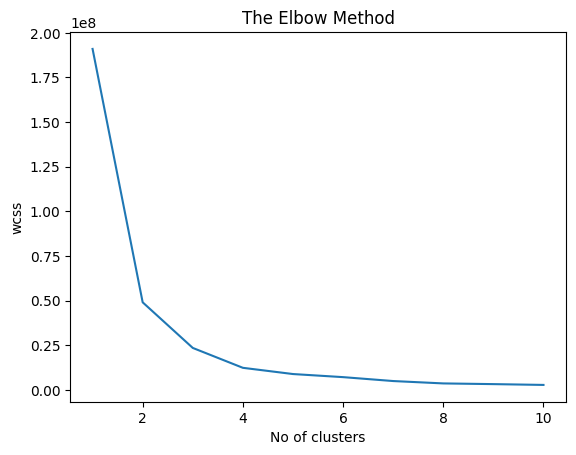

In [66]:
from  sklearn.cluster import KMeans
wcss = []
for i in range(1,11):
  Kmeans = KMeans(n_clusters=i,init='k-means++',max_iter=300, random_state=42)
  Kmeans.fit(X)
  wcss.append(Kmeans.inertia_)
plt.plot(range(1,11), wcss)
plt.title('The Elbow Method')
plt.xlabel('No of clusters')
plt.ylabel('wcss')
plt.show()

In [67]:
#Apply k means to the cars and dataset

optimal_clusters = 3  # Selected after inspecting the elbow graph

kmeans = KMeans(n_clusters=optimal_clusters,
                init='k-means++',
                max_iter=300,
                random_state=42)

y_kmeans = kmeans.fit_predict(X)



In [68]:
print(y_kmeans)

[2 1 0 2 1 2 2 2 0 1 1 1 2 2 0 2 1 0 1 1 1 0 0 2 1 1 1 2 0 1 1 0 1 0 1 0 1
 0 2 0 2 2 2 0 0 0 2 1 1 0 2 0 2 1 2 2 0 1 1 2 0 1 0 1 2 0 1 1 1 2 0 0 1 1
 1 0 0 1 1 1 2 2 0 0 1 1 0 0 1 0 1 1 2 0 1 2 2 0 2 2 2 2 1 1 1 0 1 1 0 0 1
 0 2 1 1 2 0 0 1 2 1 1 2 0 1 1 2 1 1 1 1 0 2 2 2 2 1 0 0 0 0 1 0 1 2 0 0 0
 2 0 1 1 2 0 1 0 1 1 0 0 0 2 0 0 1 0 0 0 0 1 1 0 0 1 1 1 2 2 0 1 0 1 2 0 1
 0 0 2 2 2 0 0 2 2 2 1 1 1 1 1 1 0 0 2 1 2 1 0 2 0 0 0 1 1 0 0 1 2 0 2 0 0
 2 2 2 1 2 1 0 0 0 0 0 2 0 1 2 0 1 1 2 0 2 0 2 0 2 1 1 1 1 0 0 2 0 1 2 1 0
 0 0]


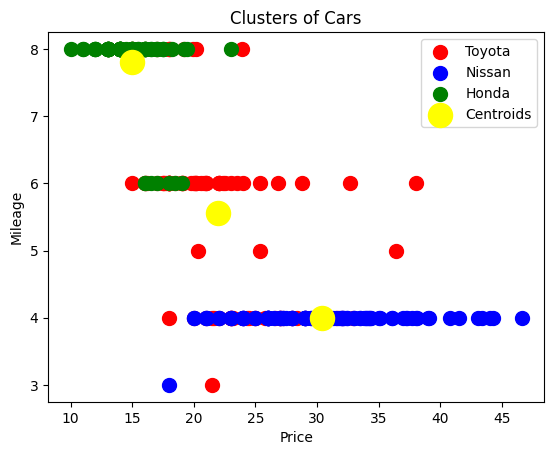

In [69]:
plt.scatter(X.iloc[y_kmeans == 0, 0], X.iloc[y_kmeans == 0, 1],
            s=100, c='red', label='Toyota')

plt.scatter(X.iloc[y_kmeans == 1, 0], X.iloc[y_kmeans == 1, 1],
            s=100, c='blue', label='Nissan')

plt.scatter(X.iloc[y_kmeans == 2, 0], X.iloc[y_kmeans == 2, 1],
            s=100, c='green', label='Honda')

plt.scatter(kmeans.cluster_centers_[:, 0],
            kmeans.cluster_centers_[:, 1],
            s=300, c='yellow', label='Centroids')

plt.title('Clusters of Cars')
plt.legend()
x_label = 'Price'
y_label = 'Mileage'
plt.xlabel(x_label)
plt.ylabel(y_label)
plt.show()

In [70]:
print("Number of clusters:", kmeans.n_clusters)
print("Centroid shape:", kmeans.cluster_centers_.shape)
print("Unique cluster labels:", np.unique(y_kmeans))

Number of clusters: 3
Centroid shape: (3, 7)
Unique cluster labels: [0 1 2]
